In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
df = pd.read_csv('missing_value_imputation_data.csv')

In [3]:
df.shape

(3554, 19)

In [4]:
df.head()

,property_type,society,sector,price,price_per_sqft,bedRoom,bathroom,balcony,floorNum,agePossession,built_up_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
0,flat,gls arawali homes,sohna road,0.35,7000.0,2,2,2,5.0,Relatively New,556.0,0,0,0,0,0,0,30,6
1,flat,the lions cghs,sector 56,2.05,8542.0,4,4,3+,8.0,Moderately Old,2667.0,0,0,0,0,0,0,49,47
2,flat,dlf new town heights,sector 90,1.25,6477.0,3,3,3+,17.0,Relatively New,1700.0,1,0,1,0,0,0,65,6
3,flat,sagar apartment,sector 56,1.45,7250.0,3,3,3+,7.0,Old Property,1900.0,1,1,1,0,1,0,166,47
4,flat,sare crescent parc,sector 92,0.66,4977.0,3,2,2,15.0,Relatively New,1473.0,0,0,0,0,0,1,44,8


In [5]:
latlong = pd.read_csv('latlong.csv')

In [6]:
latlong

,sector,coordinates
0,sector 1,"28.3663° N, 76.9456° E"
1,sector 2,"28.5095° N, 77.0320° E"
2,sector 3,"28.4909° N, 77.0176° E"
3,sector 4,"28.4738° N, 77.0107° E"
4,sector 5,"28.4794° N, 77.0176° E"
...,...,...
124,sector 113,"28.5287° N, 77.0233° E"
125,sector 114,"28.5334° N, 77.0118° E"
126,sector 115,"28.5385° N, 77.0061° E"
127,gwal pahari,"28.4484° N, 77.0210° E"


In [7]:
latlong['latitude'] = latlong['coordinates'].str.split(',').str.get(0).str.split('°').str.get(0).astype('float')

In [8]:
latlong['longitude'] = latlong['coordinates'].str.split(',').str.get(1).str.split('°').str.get(0).astype('float')

In [9]:
latlong.head()

,sector,coordinates,latitude,longitude
0,sector 1,"28.3663° N, 76.9456° E",28.3663,76.9456
1,sector 2,"28.5095° N, 77.0320° E",28.5095,77.0320
2,sector 3,"28.4909° N, 77.0176° E",28.4909,77.0176
3,sector 4,"28.4738° N, 77.0107° E",28.4738,77.0107
4,sector 5,"28.4794° N, 77.0176° E",28.4794,77.0176


In [10]:
new_df = df.merge(latlong, on='sector')

In [12]:
group_df = new_df.groupby('sector')[[
    'price',
    'price_per_sqft',
    'built_up_area',
    'latitude',
    'longitude'
]].mean().reset_index()

In [13]:
group_df

,sector,price,price_per_sqft,built_up_area,latitude,longitude
0,gwal pahari,3.192222,9585.777778,3056.166667,28.4484,77.0210
1,manesar,0.962258,4608.064516,2027.367742,28.3515,76.9428
2,sector 1,1.860000,8249.833333,2327.833333,28.3663,76.9456
3,sector 102,1.696682,10603.766355,1556.130841,28.4750,76.9715
4,sector 103,1.495119,7445.738095,1865.428571,28.4949,76.9845
...,...,...,...,...,...,...
100,sector 92,0.934030,5928.310000,1571.341800,28.4079,76.9153
101,sector 93,0.849444,8009.222222,1017.000000,28.4153,76.9326
102,sector 95,0.480818,5602.490909,995.981818,28.4172,76.9081
103,sector 99,1.488333,6798.250000,1802.666667,28.4640,76.9614


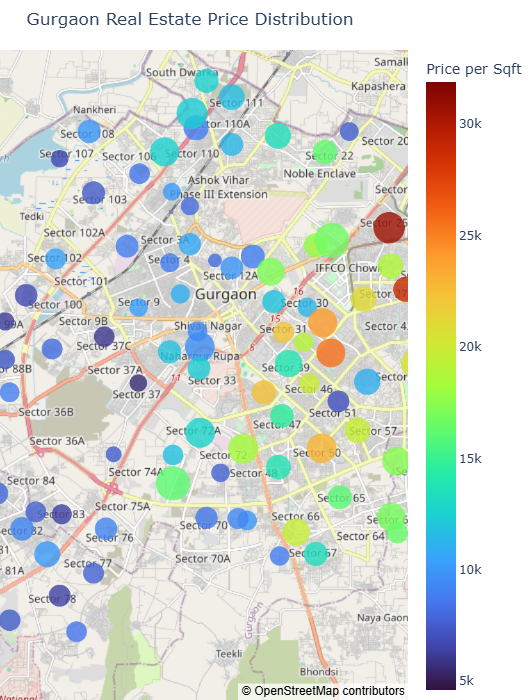

In [16]:
fig = px.scatter_map(
    group_df,
    lat="latitude",
    lon="longitude",
    color="price_per_sqft",
    size="built_up_area",
    hover_name="sector",
    hover_data={
        "price": ":,.2f",
        "price_per_sqft": ":,.2f",
        "built_up_area": ":,.0f",
        "latitude": False,
        "longitude": False
    },
    color_continuous_scale="Turbo",
    size_max=25,
    zoom=11,
    map_style="open-street-map",
    title="Gurgaon Real Estate Price Distribution"
)

fig.update_layout(
    height=700,
    margin={"r": 0, "t": 50, "l": 0, "b": 0},
    coloraxis_colorbar=dict(
        title="Price per Sqft"
    )
)

fig.update_traces(
    marker=dict(
        opacity=0.8
    )
)

fig.show()


In [17]:
new_df.to_csv('data_viz1.csv',index=False)

In [18]:
df1 = pd.read_csv('merged_flats_houses_data.csv')

In [19]:
df1.head()

,property_name,property_type,society,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,address,floorNum,facing,agePossession,nearbyLocations,description,furnishDetails,features,rating
0,2 BHK Flat in Sohna,flat,gls arawali homes,0.35,7000.0,500.0,Super Built up area 567(52.68 sq.m.)Built Up a...,2,2,2,not available,"502, Sohna, Gurgaon, Haryana",5.0,NaN,1 to 5 Year Old,"['Huda City Centre', 'Golf Course Road', 'Delh...",The flat is full furnished and ready to move,[],"['Security / Fire Alarm', 'Lift(s)', 'Maintena...","['Green Area5 out of 5', 'Construction4 out of..."
1,4 BHK Flat in Sector 56 Gurgaon,flat,the lions cghs,2.05,8541.0,2400.0,Carpet area: 2400 (222.97 sq.m.),4,4,3+,not available,"Sector 56 Gurgaon, Gurgaon, Haryana",8.0,West,5 to 10 Year Old,"['Sector metro station', 'Sector metro station...",Check out this 4 bhk apartment for sale in the...,"['1 Water Purifier', '7 Fan', '1 Exhaust Fan',...","['Feng Shui / Vaastu Compliant', 'Security / F...","['Environment4 out of 5', 'Lifestyle5 out of 5..."
2,3 BHK Flat in Sector 90 Gurgaon,flat,dlf new town heights,1.25,6476.0,1930.0,Super Built up area 1930(179.3 sq.m.)Built Up ...,3,3,3+,"pooja room,servant room","Middle Floor, Sector 90 Gurgaon, Gurgaon, Haryana",17.0,South-East,1 to 5 Year Old,"['Manish Gallexie 91', 'NH-8 IMT Manesar', 'RH...",Dlf new town heights sector 90Project highligh...,NaN,"['Feng Shui / Vaastu Compliant', 'Security / F...","['Green Area5 out of 5', 'Construction4 out of..."
3,3 BHK Flat in Sector 56 Gurgaon,flat,sagar apartment,1.45,7250.0,2000.0,Super Built up area 2000(185.81 sq.m.)Built Up...,3,3,3+,"pooja room,study room,servant room,others","Sector 56, Sector 56 Gurgaon, Gurgaon, Haryana",7.0,South,10+ Year Old,"['Sector metro station', 'Sector 54 chowk metr...","Situated in sector 56 gurgaon, sagar apartment...",NaN,"['Centrally Air Conditioned', 'Water purifier'...","['Environment4 out of 5', 'Lifestyle5 out of 5..."
4,3 BHK Flat in Sector 92 Gurgaon,flat,sare crescent parc,0.66,4977.0,1326.0,Carpet area: 1326 (123.19 sq.m.),3,2,2,not available,"Sector 92 Gurgaon, Gurgaon, Haryana",15.0,North,1 to 5 Year Old,"['Yadav Clinic', 'Bangali Clinic', 'Dr. J. S. ...",Very good location and beautifully maintained ...,"['1 Water Purifier', '5 Fan', '1 Fridge', '1 E...","['Security / Fire Alarm', 'Intercom Facility',...","['Management4 out of 5', 'Green Area4 out of 5..."


In [20]:
wordcloud_df = df1.merge(df, left_index=True, right_index=True)[['features','sector']]

In [21]:
wordcloud_df.head()

,features,sector
0,"['Security / Fire Alarm', 'Lift(s)', 'Maintena...",sohna road
1,"['Feng Shui / Vaastu Compliant', 'Security / F...",sector 56
2,"['Feng Shui / Vaastu Compliant', 'Security / F...",sector 90
3,"['Centrally Air Conditioned', 'Water purifier'...",sector 56
4,"['Security / Fire Alarm', 'Intercom Facility',...",sector 92


In [22]:
import ast
main = []
for item in wordcloud_df['features'].dropna().apply(ast.literal_eval):
    main.extend(item)

In [23]:
main

['Security / Fire Alarm',
 'Lift(s)',
 'Maintenance Staff',
 'Park',
 'Visitor Parking',
 'Feng Shui / Vaastu Compliant',
 'Security / Fire Alarm',
 'Intercom Facility',
 'Lift(s)',
 'Maintenance Staff',
 'Water Storage',
 'Park',
 'Visitor Parking',
 'Feng Shui / Vaastu Compliant',
 'Security / Fire Alarm',
 'Intercom Facility',
 'Lift(s)',
 'Maintenance Staff',
 'Swimming Pool',
 'Water Storage',
 'Park',
 'Visitor Parking',
 'Fitness Centre / GYM',
 'Club house / Community Center',
 'Centrally Air Conditioned',
 'Water purifier',
 'Security / Fire Alarm',
 'Feng Shui / Vaastu Compliant',
 'Private Garden / Terrace',
 'Intercom Facility',
 'Lift(s)',
 'High Ceiling Height',
 'Maintenance Staff',
 'False Ceiling Lighting',
 'Water Storage',
 'Separate entry for servant room',
 'No open drainage around',
 'Bank Attached Property',
 'Piped-gas',
 'Internet/wi-fi connectivity',
 'Recently Renovated',
 'Visitor Parking',
 'Park',
 'Security Personnel',
 'Natural Light',
 'Airy Rooms',
 'S

In [24]:
from wordcloud import WordCloud

In [25]:
feature_text = ' '.join(main)

In [26]:
import pickle
pickle.dump(feature_text, open('feature_text.pkl','wb'))

In [27]:
feature_text

'Security / Fire Alarm Lift(s) Maintenance Staff Park Visitor Parking Feng Shui / Vaastu Compliant Security / Fire Alarm Intercom Facility Lift(s) Maintenance Staff Water Storage Park Visitor Parking Feng Shui / Vaastu Compliant Security / Fire Alarm Intercom Facility Lift(s) Maintenance Staff Swimming Pool Water Storage Park Visitor Parking Fitness Centre / GYM Club house / Community Center Centrally Air Conditioned Water purifier Security / Fire Alarm Feng Shui / Vaastu Compliant Private Garden / Terrace Intercom Facility Lift(s) High Ceiling Height Maintenance Staff False Ceiling Lighting Water Storage Separate entry for servant room No open drainage around Bank Attached Property Piped-gas Internet/wi-fi connectivity Recently Renovated Visitor Parking Park Security Personnel Natural Light Airy Rooms Spacious Interiors Low Density Society Waste Disposal Rain Water Harvesting Water softening plant Shopping Centre Fitness Centre / GYM Club house / Community Center Security / Fire Alarm

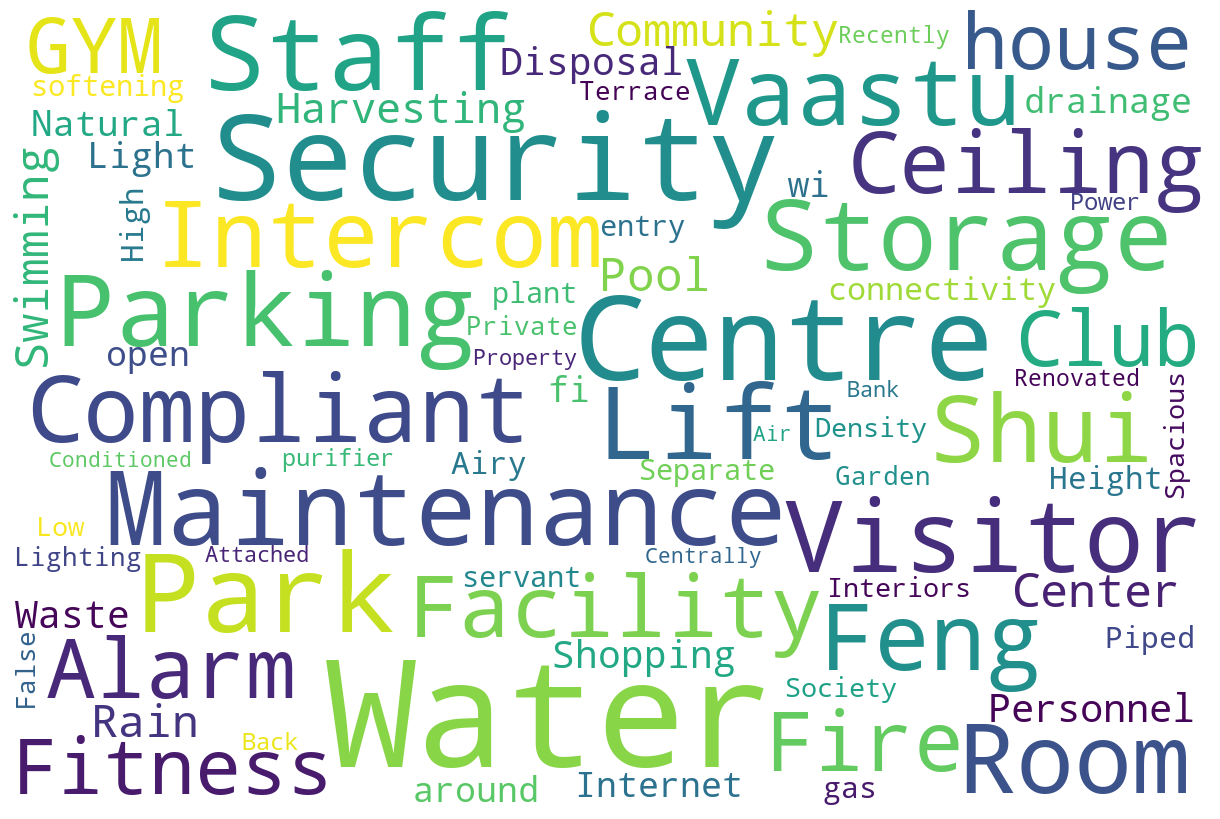

In [28]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

plt.rcParams["font.family"] = "Arial"

wordcloud = WordCloud(
    width=1200,
    height=800,
    background_color="white",
    stopwords=STOPWORDS.union({'s'}),
    min_font_size=10,
    max_font_size=150,
    max_words=200,
    colormap='viridis',
    contour_width=1,
    contour_color='steelblue',
    prefer_horizontal=0.9,
    relative_scaling=0.5,
    collocations=False
).generate(feature_text)

plt.figure(figsize=(12, 8), facecolor='white')

plt.imshow(wordcloud, interpolation='bilinear')

plt.axis("off")
plt.tight_layout(pad=0)

plt.show()

In [29]:

import streamlit as st
import matplotlib.pyplot as plt
import numpy as np

from wordcloud import WordCloud
from PIL import Image, ImageDraw

# Create house-shaped mask
width, height = 1200, 1000

mask_image = Image.new("RGB", (width, height), "white")
draw = ImageDraw.Draw(mask_image)

# House shape: roof + walls + base
house_points = [
    (600, 40),    # Roof top
    (1100, 420),  # Roof right
    (1000, 420),
    (1000, 900),  # Right wall
    (200, 900),   # Left wall
    (200, 420),
    (100, 420)    # Roof left
]

draw.polygon(house_points, fill="black")

# Convert image into NumPy mask
house_mask = np.array(mask_image)

# Generate WordCloud
wordcloud = WordCloud(
    width=1200,
    height=1000,
    background_color="white",
    mask=house_mask,
    stopwords=STOPWORDS.union({'s'}),
    min_font_size=10,
    max_font_size=150,
    max_words=200,
    colormap="viridis",
    prefer_horizontal=0.9,
    relative_scaling=0.5,
    collocations=False,
    contour_width=3,
    contour_color="#0F766E"
).generate(feature_text)

# Display
fig, ax = plt.subplots(figsize=(12, 10))

fig.patch.set_facecolor("white")
ax.imshow(wordcloud, interpolation="bilinear")

ax.axis("off")
plt.tight_layout(pad=0)

st.pyplot(fig)
plt.close(fig)


2026-11-12 01:09:17.056 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-12 01:09:19.041 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-12 01:09:20.450 
  command:

    streamlit run C:\Users\THARUN TEJA S\.conda\envs\aiml_env\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-11-12 01:09:20.452 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-12 01:09:20.455 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [30]:
# Create house mask
width, height = 1000, 850

mask_image = Image.new("L", (width, height), 255)
draw = ImageDraw.Draw(mask_image)

# House roof
draw.polygon(
    [(500, 30), (950, 400), (50, 400)],
    fill=0
)

# House body
draw.rectangle(
    [(140, 350), (860, 810)],
    fill=0
)

# Convert to numpy array
house_mask = np.array(mask_image)

# Generate WordCloud
wordcloud = WordCloud(
    width=width,
    height=height,
    mask=house_mask,
    background_color="white",
    stopwords=STOPWORDS.union({'s'}),
    max_words=200,
    max_font_size=130,
    min_font_size=10,
    colormap="turbo",
    prefer_horizontal=0.9,
    relative_scaling=0.5,
    collocations=False,
    contour_width=4,
    contour_color="#0F766E"
).generate(feature_text)

# Display in Streamlit
fig, ax = plt.subplots(figsize=(11, 9))

ax.imshow(wordcloud, interpolation="bilinear")
ax.axis("off")

fig.patch.set_facecolor("white")
plt.tight_layout(pad=0)

st.pyplot(fig)
plt.close(fig)


2026-11-12 01:14:06.636 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-12 01:14:08.225 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-12 01:14:08.228 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-12 01:14:08.229 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
